In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")
print("Dataset shape:", df.shape)
baseline_df = pd.read_csv("../data/sram_baseline_dataset.csv")
print("Original dataset:", df.shape)
print("Baseline dataset:", baseline_df.shape)

Dataset shape: (450, 33)
Original dataset: (450, 33)
Baseline dataset: (450, 17)


In [5]:
# Features
X = baseline_df.drop(columns=["fault_class"])

# Target
y = baseline_df["fault_class"]

# PVT corner grouping
groups = df["corner_id"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique PVT corners:", groups.nunique())

X shape: (450, 16)
y shape: (450,)
Unique PVT corners: 15


In [6]:
corner_distribution = pd.crosstab(
    groups,
    y
)

print(corner_distribution)

fault_class  0   1  2  3  4
corner_id                  
C_0C_0P9V    1  12  5  6  6
C_0C_1P0V    1  12  5  6  6
C_0C_1P1V    1  12  5  6  6
C_125C_0P9V  1  12  5  6  6
C_125C_1P0V  1  12  5  6  6
C_125C_1P1V  1  12  5  6  6
C_27C_0P9V   1  12  5  6  6
C_27C_1P0V   1  12  5  6  6
C_27C_1P1V   1  12  5  6  6
C_75C_0P9V   1  12  5  6  6
C_75C_1P0V   1  12  5  6  6
C_75C_1P1V   1  12  5  6  6
C_M40C_0P9V  1  12  5  6  6
C_M40C_1P0V  1  12  5  6  6
C_M40C_1P1V  1  12  5  6  6


In [7]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining corners:", sorted(train_groups.unique()))
print("Testing corners:", sorted(test_groups.unique()))

print(
    "\nOverlapping corners:",
    set(train_groups.unique()) & set(test_groups.unique())
)

Training samples: 360
Testing samples: 90

Training corners: ['C_0C_1P0V', 'C_0C_1P1V', 'C_125C_0P9V', 'C_125C_1P0V', 'C_27C_0P9V', 'C_27C_1P0V', 'C_27C_1P1V', 'C_75C_0P9V', 'C_75C_1P1V', 'C_M40C_0P9V', 'C_M40C_1P0V', 'C_M40C_1P1V']
Testing corners: ['C_0C_0P9V', 'C_125C_1P1V', 'C_75C_1P0V']

Overlapping corners: set()


In [8]:
print("Training distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

Training distribution:
fault_class
0     12
1    144
2     60
3     72
4     72
Name: count, dtype: int64

Testing distribution:
fault_class
0     3
1    36
2    15
3    18
4    18
Name: count, dtype: int64


In [9]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

ValueError: could not convert string to float: 'ood'

In [10]:
print("X_train type:", type(X_train))
print("X_train shape:", X_train.shape)

print("\ny_train type:", type(y_train))
print("y_train shape:", y_train.shape)

print("\ny_train sample:")
print(y_train[:10])

print("\ny_train data type:")
print(y_train.dtype if hasattr(y_train, "dtype") else "Multiple columns")

X_train type: <class 'pandas.core.frame.DataFrame'>
X_train shape: (360, 16)

y_train type: <class 'pandas.core.series.Series'>
y_train shape: (360,)

y_train sample:
0    0
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: fault_class, dtype: int64

y_train data type:
int64


In [11]:
y_train = pd.Series(y_train.squeeze()).astype(int)
y_test = pd.Series(y_test.squeeze()).astype(int)

print("Corrected y_train shape:", y_train.shape)
print("Corrected y_test shape:", y_test.shape)

Corrected y_train shape: (360,)
Corrected y_test shape: (90,)


In [12]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

ValueError: could not convert string to float: 'ood'

In [13]:
# ==========================================
# ENCODE CATEGORICAL FEATURES
# ==========================================

# Convert categorical columns into numerical columns
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["pvt_type"],
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["pvt_type"],
    drop_first=True,
    dtype=int
)

# Ensure both datasets have identical columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Before encoding:", X_train.shape)
print("After encoding:", X_train_encoded.shape)

print("\nEncoded features:")
print(X_train_encoded.columns.tolist())

Before encoding: (360, 16)
After encoding: (360, 16)

Encoded features:
['vdd_v', 'temperature_c', 'i_ddq_uA', 't_write_ps', 'i_write_peak_mA', 'dv_bl_strobe_mV', 't_sense_ps', 'v_bump_mV', 'hold_pass', 'write_pass', 'read_stable_pass', 'snm_hold_v', 'snm_read_v', 'snm_asym_read_v', 'is_bistable', 'pvt_type_ood']


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using encoded features
rf_model.fit(X_train_encoded, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [15]:
y_train_pred = rf_model.predict(X_train_encoded)
y_test_pred = rf_model.predict(X_test_encoded)

print("Training accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing accuracy:",
      accuracy_score(y_test, y_test_pred))

Training accuracy: 1.0
Testing accuracy: 0.7888888888888889


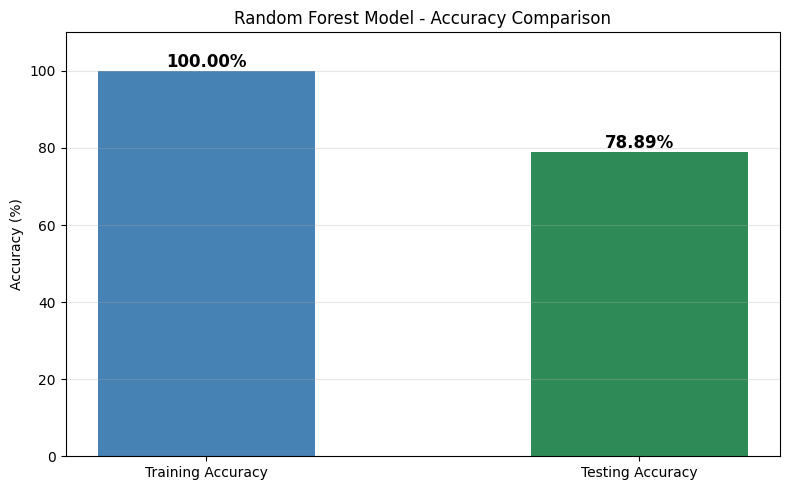

In [16]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Calculate accuracy percentages
train_accuracy = accuracy_score(y_train, y_train_pred) * 100
test_accuracy = accuracy_score(y_test, y_test_pred) * 100

labels = ["Training Accuracy", "Testing Accuracy"]
values = [train_accuracy, test_accuracy]

# Plot
plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    values,
    width=0.5,
    color=["steelblue", "seagreen"]
)

# Display percentages
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.ylim(0, 110)
plt.ylabel("Accuracy (%)")
plt.title("Random Forest Model - Accuracy Comparison")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

# Apply PCA
pca = PCA(n_components=3)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal variance explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Explained variance ratio:
[0.55509969 0.14739456 0.07088075]

Total variance explained: 77.34 %


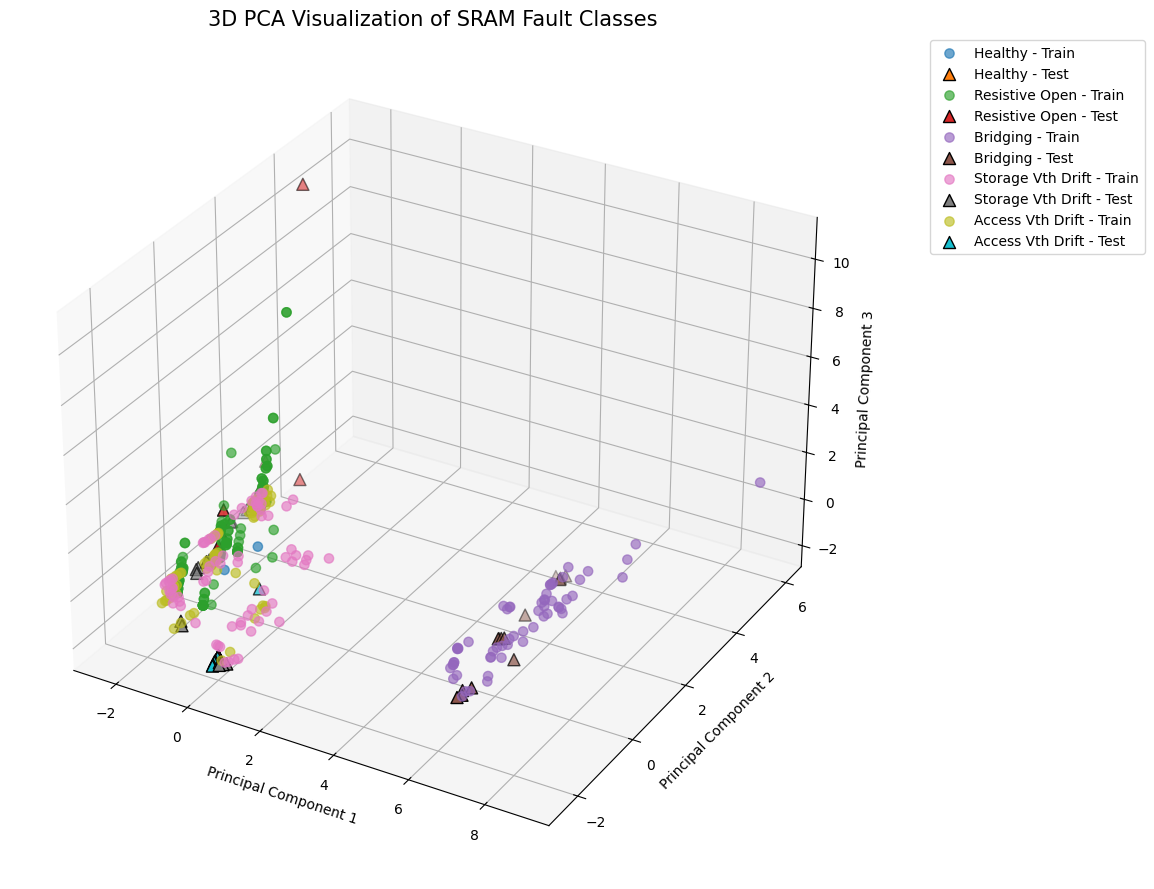

In [19]:
# Fault class names
fault_labels = {
    0: "Healthy",
    1: "Resistive Open",
    2: "Bridging",
    3: "Storage Vth Drift",
    4: "Access Vth Drift"
}

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Plot training and testing samples
for class_id, class_name in fault_labels.items():

    train_mask = (y_train.to_numpy() == class_id)
    test_mask = (y_test.to_numpy() == class_id)

    # Training samples
    ax.scatter(
        X_train_pca[train_mask, 0],
        X_train_pca[train_mask, 1],
        X_train_pca[train_mask, 2],
        label=f"{class_name} - Train",
        marker="o",
        alpha=0.65,
        s=45
    )

    # Testing samples
    ax.scatter(
        X_test_pca[test_mask, 0],
        X_test_pca[test_mask, 1],
        X_test_pca[test_mask, 2],
        label=f"{class_name} - Test",
        marker="^",
        s=75,
        edgecolors="black"
    )

ax.set_title(
    "3D PCA Visualization of SRAM Fault Classes",
    fontsize=15
)

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")

ax.legend(bbox_to_anchor=(1.35, 1), loc="upper right")
plt.tight_layout()
plt.show()

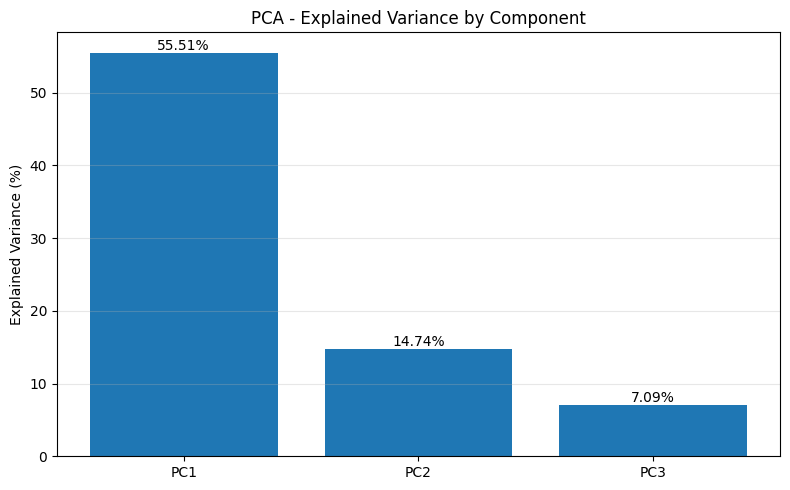

In [20]:
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["PC1", "PC2", "PC3"],
    variance
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.ylabel("Explained Variance (%)")
plt.title("PCA - Explained Variance by Component")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

class_names = [
    "Healthy",
    "Resistive Open",
    "Bridging",
    "Storage Vth Drift",
    "Access Vth Drift"
]

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

                   precision    recall  f1-score   support

          Healthy       0.00      0.00      0.00         3
   Resistive Open       1.00      0.61      0.76        36
         Bridging       1.00      1.00      1.00        15
Storage Vth Drift       0.53      1.00      0.69        18
 Access Vth Drift       0.84      0.89      0.86        18

         accuracy                           0.79        90
        macro avg       0.67      0.70      0.66        90
     weighted avg       0.84      0.79      0.78        90



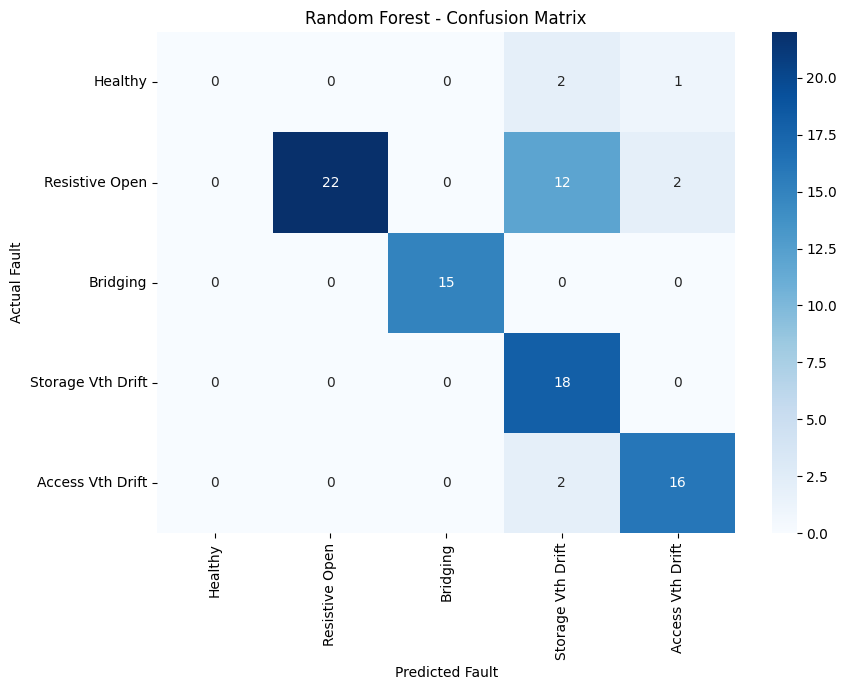

In [22]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision (Macro)": precision_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Recall (Macro)": recall_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "F1 Score (Macro)": f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "F1 Score (Weighted)": f1_score(
        y_test, y_test_pred, average="weighted", zero_division=0
    )
}

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f} ({value*100:.2f}%)")

Accuracy: 0.7889 (78.89%)
Precision (Macro): 0.6743 (67.43%)
Recall (Macro): 0.7000 (70.00%)
F1 Score (Macro): 0.6632 (66.32%)
F1 Score (Weighted): 0.7815 (78.15%)


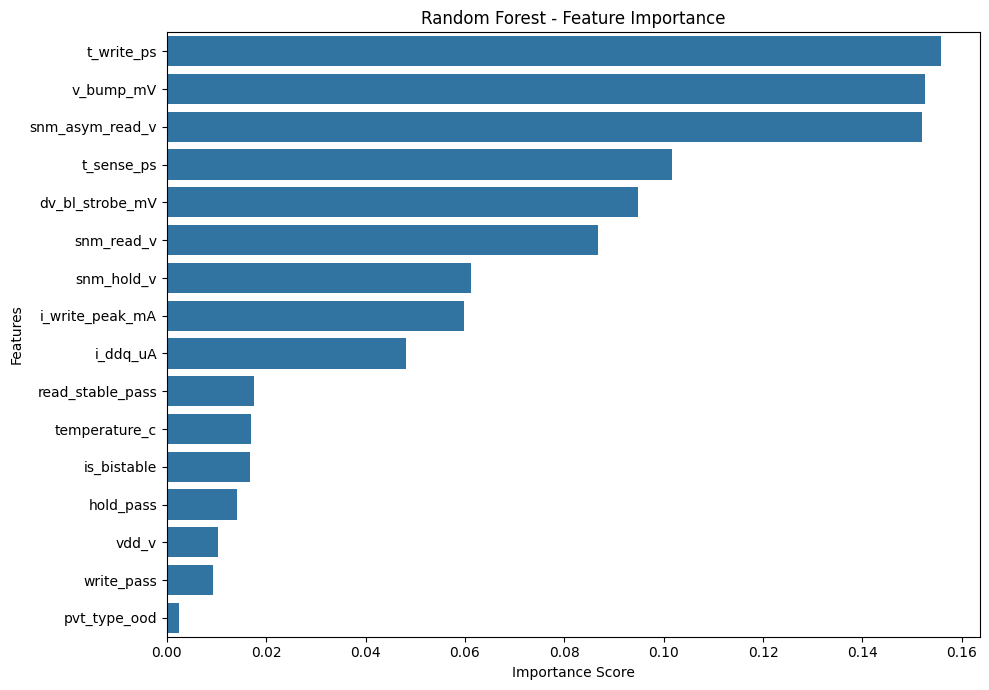

             Feature  Importance
3         t_write_ps    0.155871
7          v_bump_mV    0.152498
13   snm_asym_read_v    0.151956
6         t_sense_ps    0.101708
5    dv_bl_strobe_mV    0.094848
12        snm_read_v    0.086792
11        snm_hold_v    0.061157
4    i_write_peak_mA    0.059708
2           i_ddq_uA    0.048194
10  read_stable_pass    0.017546
1      temperature_c    0.016958
14       is_bistable    0.016710
8          hold_pass    0.014160
0              vdd_v    0.010215
9         write_pass    0.009188
15      pvt_type_ood    0.002491


In [24]:
importance_df = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(importance_df)

In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_tuned = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_tuned.fit(X_train_encoded, y_train)

print("Regularized Random Forest trained!")

Regularized Random Forest trained!


In [26]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Predictions
y_train_tuned = rf_tuned.predict(X_train_encoded)
y_test_tuned = rf_tuned.predict(X_test_encoded)

# Accuracy
train_acc = accuracy_score(y_train, y_train_tuned)
test_acc = accuracy_score(y_test, y_test_tuned)

# F1 scores
macro_f1 = f1_score(
    y_test, y_test_tuned, average="macro", zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_test_tuned, average="weighted", zero_division=0
)

print("Training Accuracy:", round(train_acc * 100, 2), "%")
print("Testing Accuracy:", round(test_acc * 100, 2), "%")
print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_tuned,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Healthy",
        "Resistive Open",
        "Bridging",
        "Storage Vth Drift",
        "Access Vth Drift"
    ],
    zero_division=0
))

Training Accuracy: 94.17 %
Testing Accuracy: 75.56 %
Macro F1: 0.6415
Weighted F1: 0.7599

Classification Report:
                   precision    recall  f1-score   support

          Healthy       0.00      0.00      0.00         3
   Resistive Open       1.00      0.61      0.76        36
         Bridging       1.00      1.00      1.00        15
Storage Vth Drift       0.55      1.00      0.71        18
 Access Vth Drift       0.76      0.72      0.74        18

         accuracy                           0.76        90
        macro avg       0.66      0.67      0.64        90
     weighted avg       0.83      0.76      0.76        90



In [27]:
comparison = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Macro F1",
        "Weighted F1"
    ],
    "Original Random Forest": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro", zero_division=0),
        f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
    ],
    "Regularized Random Forest": [
        accuracy_score(y_train, y_train_tuned),
        accuracy_score(y_test, y_test_tuned),
        macro_f1,
        weighted_f1
    ]
})

print(comparison.round(4))

              Metric  Original Random Forest  Regularized Random Forest
0  Training Accuracy                  1.0000                     0.9417
1   Testing Accuracy                  0.7889                     0.7556
2           Macro F1                  0.6632                     0.6415
3        Weighted F1                  0.7815                     0.7599


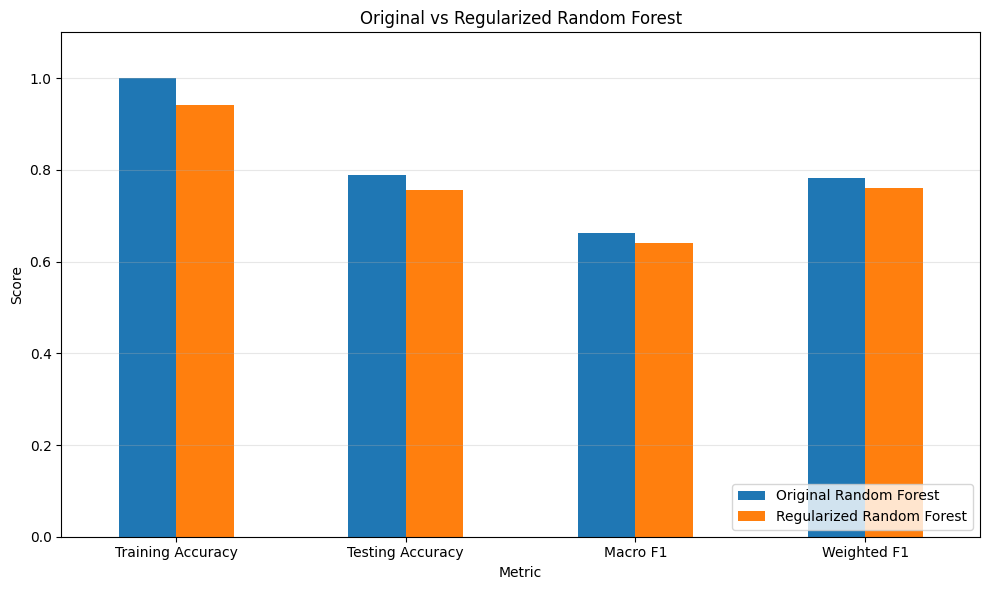

In [28]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.1)
)

plt.title("Original vs Regularized Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [29]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [30]:
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [31]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_encoded, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [32]:
# Predictions
y_train_xgb = xgb_model.predict(X_train_encoded)
y_test_xgb = xgb_model.predict(X_test_encoded)

# Accuracy
train_accuracy = accuracy_score(y_train, y_train_xgb)
test_accuracy = accuracy_score(y_test, y_test_xgb)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print(
    "Macro F1:",
    round(f1_score(y_test, y_test_xgb, average="macro", zero_division=0), 4)
)

Training Accuracy: 99.72 %
Testing Accuracy: 77.78 %
Macro F1: 0.6496


In [33]:
class_names = [
    "Healthy",
    "Resistive Open",
    "Bridging",
    "Storage Vth Drift",
    "Access Vth Drift"
]

print(classification_report(
    y_test,
    y_test_xgb,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

                   precision    recall  f1-score   support

          Healthy       0.00      0.00      0.00         3
   Resistive Open       1.00      0.61      0.76        36
         Bridging       1.00      1.00      1.00        15
Storage Vth Drift       0.56      1.00      0.72        18
 Access Vth Drift       0.71      0.83      0.77        18

         accuracy                           0.78        90
        macro avg       0.66      0.69      0.65        90
     weighted avg       0.82      0.78      0.77        90



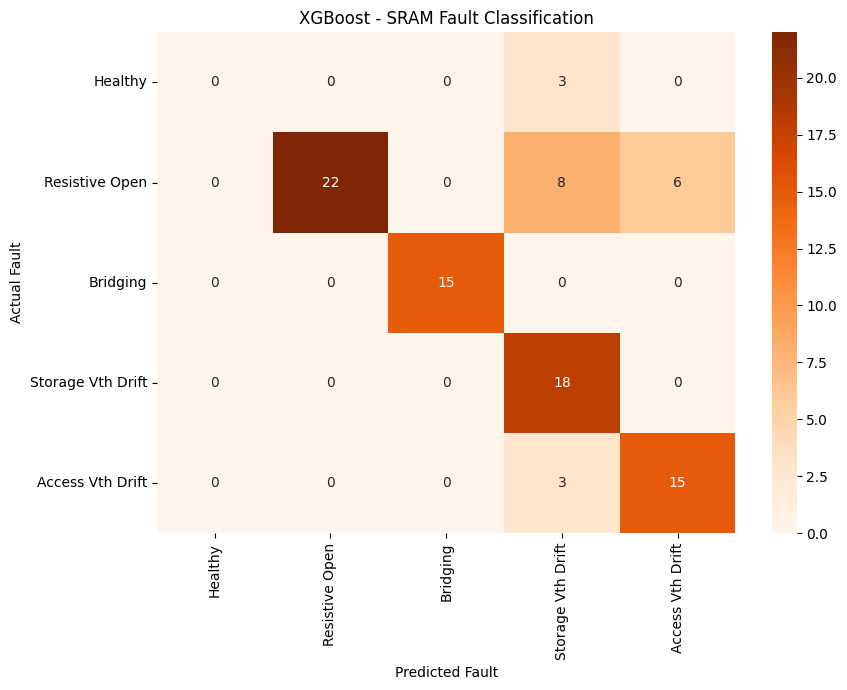

In [34]:
cm = confusion_matrix(
    y_test,
    y_test_xgb,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Fault")
plt.ylabel("Actual Fault")
plt.title("XGBoost - SRAM Fault Classification")
plt.tight_layout()
plt.show()

In [35]:
comparison = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Macro F1",
        "Weighted F1"
    ],

    "Random Forest": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro", zero_division=0),
        f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
    ],

    "XGBoost": [
        accuracy_score(y_train, y_train_xgb),
        accuracy_score(y_test, y_test_xgb),
        f1_score(y_test, y_test_xgb, average="macro", zero_division=0),
        f1_score(y_test, y_test_xgb, average="weighted", zero_division=0)
    ]
})

print(comparison.round(4))

              Metric  Random Forest  XGBoost
0  Training Accuracy         1.0000   0.9972
1   Testing Accuracy         0.7889   0.7778
2           Macro F1         0.6632   0.6496
3        Weighted F1         0.7815   0.7680


In [38]:
comparison = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Macro F1",
        "Weighted F1"
    ],

    "Random Forest": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred, average="macro", zero_division=0),
        f1_score(y_test, y_test_pred, average="weighted", zero_division=0)
    ],

    "XGBoost": [
        accuracy_score(y_train, y_train_xgb),
        accuracy_score(y_test, y_test_xgb),
        f1_score(y_test, y_test_xgb, average="macro", zero_division=0),
        f1_score(y_test, y_test_xgb, average="weighted", zero_division=0)
    ]
})

print(comparison.round(4))

              Metric  Random Forest  XGBoost
0  Training Accuracy         1.0000   0.9972
1   Testing Accuracy         0.7889   0.7778
2           Macro F1         0.6632   0.6496
3        Weighted F1         0.7815   0.7680


In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Random Forest": rf_model,
    "Regularized Random Forest": rf_tuned,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    y_train_pred = model.predict(X_train_encoded)
    y_test_pred = model.predict(X_test_encoded)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision (Macro)": precision_score(
            y_test, y_test_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_test_pred, average="macro", zero_division=0
        ),
        "F1 Score (Macro)": f1_score(
            y_test, y_test_pred, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.round(4)

comparison_df

,Model,Train Accuracy,Test Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Random Forest,1.0000,0.7889,0.6743,0.7000,0.6632
1,Regularized Random Forest,0.9417,0.7556,0.6620,0.6667,0.6415
2,XGBoost,0.9972,0.7778,0.6554,0.6889,0.6496


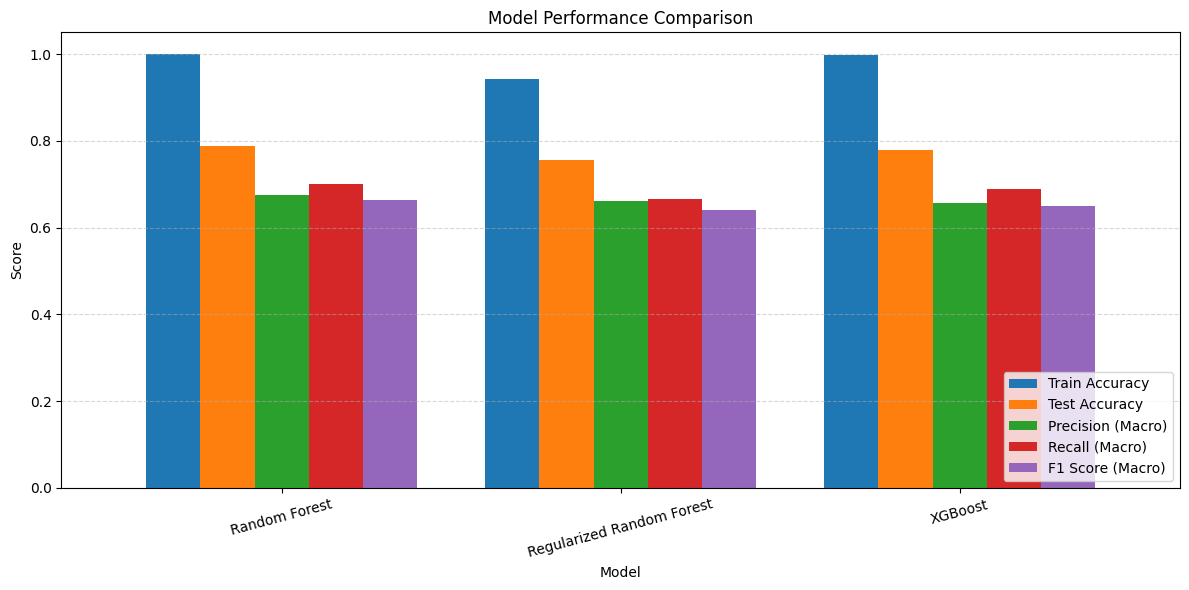

In [40]:
import matplotlib.pyplot as plt

metrics = [
    "Train Accuracy",
    "Test Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1 Score (Macro)"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [41]:
comparison_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print(comparison_df)

                       Model  Train Accuracy  Test Accuracy  \
0              Random Forest          1.0000         0.7889   
1  Regularized Random Forest          0.9417         0.7556   
2                    XGBoost          0.9972         0.7778   

   Precision (Macro)  Recall (Macro)  F1 Score (Macro)  
0             0.6743          0.7000            0.6632  
1             0.6620          0.6667            0.6415  
2             0.6554          0.6889            0.6496  


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Random Forest": rf_model.feature_importances_,
    "Regularized RF": rf_tuned.feature_importances_,
    "XGBoost": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Random Forest",
    ascending=False
)

importance_df.head(15)

,Feature,Random Forest,Regularized RF,XGBoost
3,t_write_ps,0.155871,0.146576,0.089383
7,v_bump_mV,0.152498,0.160863,0.057647
13,snm_asym_read_v,0.151956,0.187358,0.341988
6,t_sense_ps,0.101708,0.103516,0.040215
5,dv_bl_strobe_mV,0.094848,0.082401,0.048744
12,snm_read_v,0.086792,0.085814,0.048172
11,snm_hold_v,0.061157,0.062718,0.034070
4,i_write_peak_mA,0.059708,0.052680,0.048620
2,i_ddq_uA,0.048194,0.037118,0.038814
10,read_stable_pass,0.017546,0.023384,0.010928


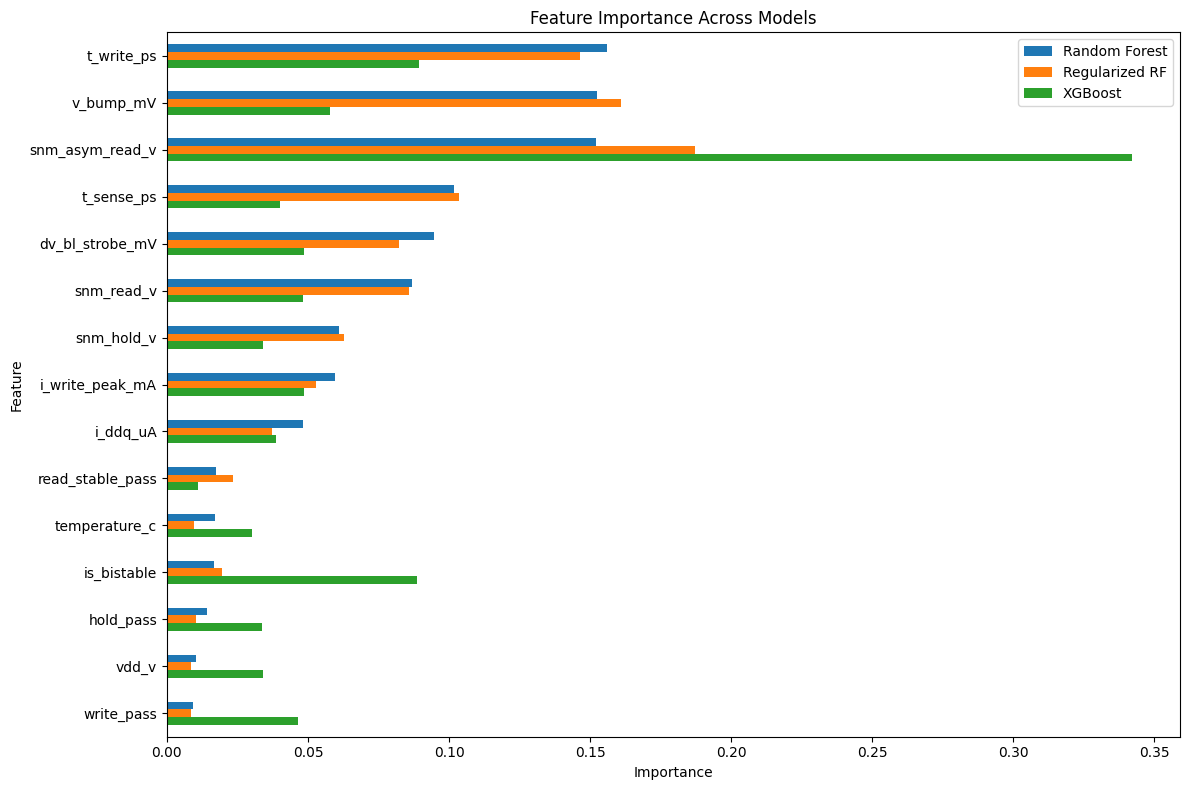

In [43]:
importance_df.set_index("Feature")[
    ["Random Forest", "Regularized RF", "XGBoost"]
].head(15).plot(
    kind="barh",
    figsize=(12, 8)
)

plt.title("Feature Importance Across Models")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [44]:
leakage_columns = [
    "hold_pass",
    "write_pass",
    "read_stable_pass",
    "is_bistable"
]

X_train_clean = X_train_encoded.drop(
    columns=leakage_columns,
    errors="ignore"
)

X_test_clean = X_test_encoded.drop(
    columns=leakage_columns,
    errors="ignore"
)

print("Original feature count:", X_train_encoded.shape[1])
print("Features after removal:", X_train_clean.shape[1])
print("Removed:", leakage_columns)

Original feature count: 16
Features after removal: 12
Removed: ['hold_pass', 'write_pass', 'read_stable_pass', 'is_bistable']


In [45]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Original Random Forest
rf_clean = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Regularized Random Forest
rf_tuned_clean = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# XGBoost
xgb_clean = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

rf_clean.fit(X_train_clean, y_train)
rf_tuned_clean.fit(X_train_clean, y_train)
xgb_clean.fit(X_train_clean, y_train)

print("All three models trained without pass/fail indicators.")

All three models trained without pass/fail indicators.


In [46]:
from sklearn.metrics import accuracy_score, f1_score

clean_models = {
    "Random Forest": rf_clean,
    "Regularized RF": rf_tuned_clean,
    "XGBoost": xgb_clean
}

clean_results = []

for name, model in clean_models.items():

    predictions = model.predict(X_test_clean)

    clean_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    })

clean_comparison = pd.DataFrame(clean_results).round(4)

clean_comparison

,Model,Test Accuracy,Macro F1
0,Random Forest,0.7889,0.6654
1,Regularized RF,0.7667,0.6601
2,XGBoost,0.7778,0.6496


In [47]:
print("BEFORE removing pass/fail indicators")
display(comparison_df)

print("AFTER removing pass/fail indicators")
display(clean_comparison)

BEFORE removing pass/fail indicators


,Model,Train Accuracy,Test Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Random Forest,1.0000,0.7889,0.6743,0.7000,0.6632
1,Regularized Random Forest,0.9417,0.7556,0.6620,0.6667,0.6415
2,XGBoost,0.9972,0.7778,0.6554,0.6889,0.6496


AFTER removing pass/fail indicators


,Model,Test Accuracy,Macro F1
0,Random Forest,0.7889,0.6654
1,Regularized RF,0.7667,0.6601
2,XGBoost,0.7778,0.6496


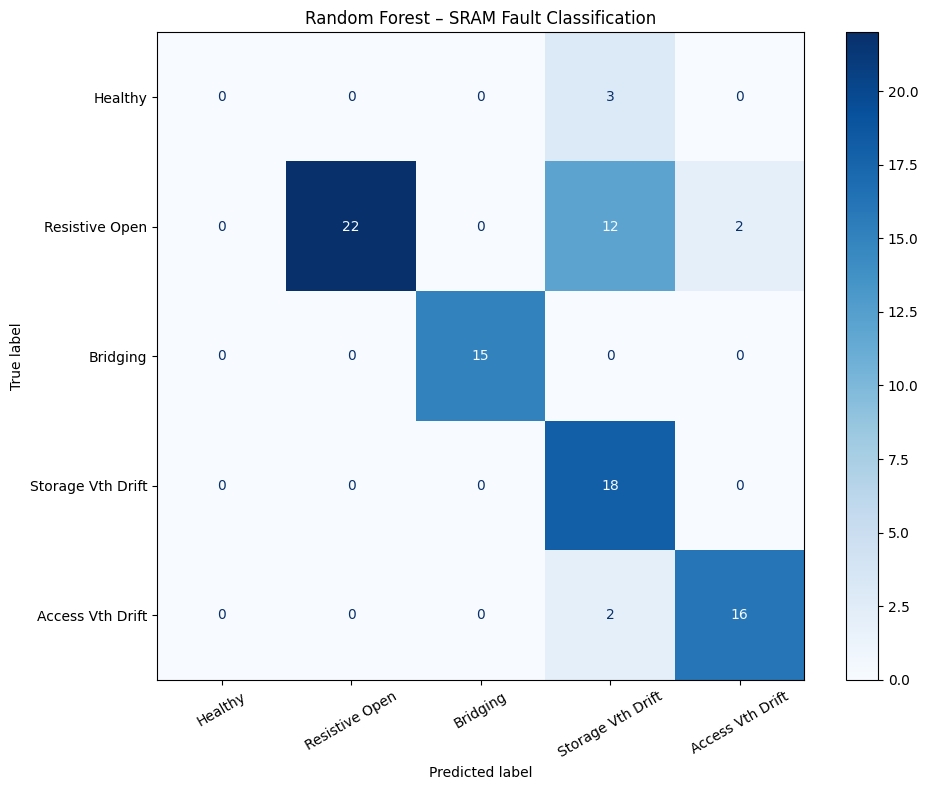

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    "Healthy",
    "Resistive Open",
    "Bridging",
    "Storage Vth Drift",
    "Access Vth Drift"
]

y_pred_rf = rf_clean.predict(X_test_clean)

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=30)
plt.title("Random Forest – SRAM Fault Classification")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

                   precision    recall  f1-score   support

          Healthy       0.00      0.00      0.00         3
   Resistive Open       1.00      0.61      0.76        36
         Bridging       1.00      1.00      1.00        15
Storage Vth Drift       0.51      1.00      0.68        18
 Access Vth Drift       0.89      0.89      0.89        18

         accuracy                           0.79        90
        macro avg       0.68      0.70      0.67        90
     weighted avg       0.85      0.79      0.78        90



In [50]:
from sklearn.model_selection import StratifiedGroupKFold

# Start with the original baseline features
X_cv = X.drop(
    columns=[
        "hold_pass",
        "write_pass",
        "read_stable_pass",
        "is_bistable"
    ],
    errors="ignore"
).copy()

# Encode categorical PVT information
X_cv = pd.get_dummies(
    X_cv,
    columns=["pvt_type"],
    drop_first=True,
    dtype=int
)

y_cv = y.copy()
groups_cv = groups.copy()

print("Feature shape:", X_cv.shape)
print("Target shape:", y_cv.shape)
print("Number of PVT corners:", groups_cv.nunique())

Feature shape: (450, 12)
Target shape: (450,)
Number of PVT corners: 15


In [51]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Regularized Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        groups=groups_cv,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Mean Macro F1": scores["test_f1_macro"].mean(),
        "Macro F1 Std": scores["test_f1_macro"].std()
    })

cv_comparison = pd.DataFrame(cv_results).round(4)

display(cv_comparison)

,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Random Forest,0.8222,0.0579,0.6828,0.0346
1,Regularized Random Forest,0.8133,0.0657,0.7112,0.0647
2,XGBoost,0.8067,0.0784,0.6848,0.0746


In [52]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import matplotlib.pyplot as plt

best_candidate = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

oof_predictions = cross_val_predict(
    best_candidate,
    X_cv,
    y_cv,
    groups=groups_cv,
    cv=cv,
    n_jobs=-1
)

class_names = [
    "Healthy",
    "Resistive Open",
    "Bridging",
    "Storage Vth Drift",
    "Access Vth Drift"
]

print(classification_report(
    y_cv,
    oof_predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

                   precision    recall  f1-score   support

          Healthy       0.17      0.13      0.15        15
   Resistive Open       0.99      0.74      0.85       180
         Bridging       1.00      1.00      1.00        75
Storage Vth Drift       0.71      0.93      0.80        90
 Access Vth Drift       0.65      0.80      0.72        90

         accuracy                           0.81       450
        macro avg       0.70      0.72      0.70       450
     weighted avg       0.84      0.81      0.82       450



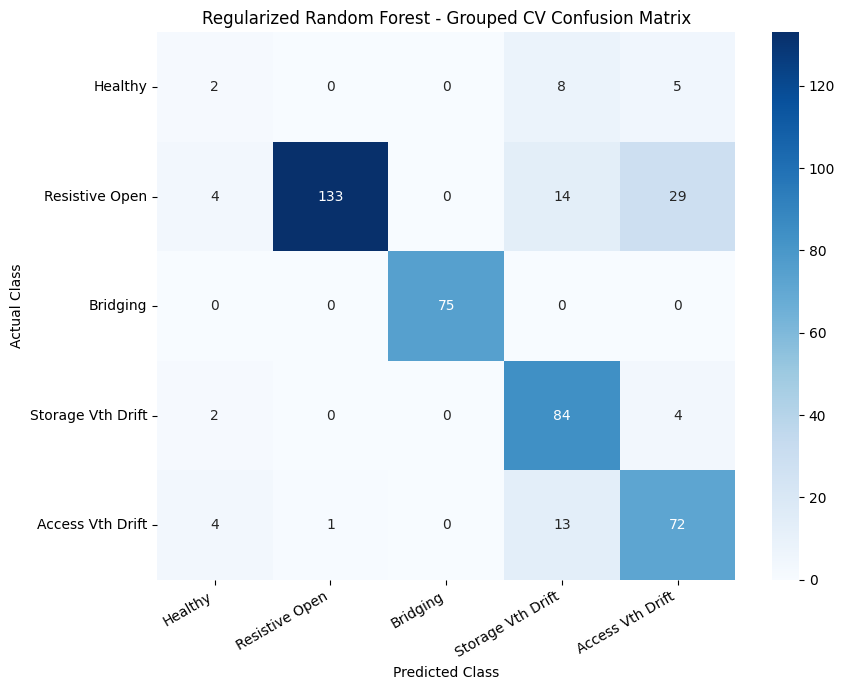

In [53]:
cm = confusion_matrix(
    y_cv,
    oof_predictions,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Regularized Random Forest - Grouped CV Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [54]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# Train the regularized RF on the complete dataset
final_candidate = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_candidate.fit(X_cv, y_cv)

# Calculate permutation importance
importance = permutation_importance(
    final_candidate,
    X_cv,
    y_cv,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_cv.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance,Std
10,snm_asym_read_v,0.229042,0.014426
7,v_bump_mV,0.081547,0.013343
3,t_write_ps,0.077021,0.018064
4,i_write_peak_mA,0.049796,0.012098
5,dv_bl_strobe_mV,0.043119,0.006588
2,i_ddq_uA,0.029094,0.009160
9,snm_read_v,0.021089,0.009249
8,snm_hold_v,0.010816,0.004068
0,vdd_v,0.006259,0.005343
6,t_sense_ps,0.004051,0.004837


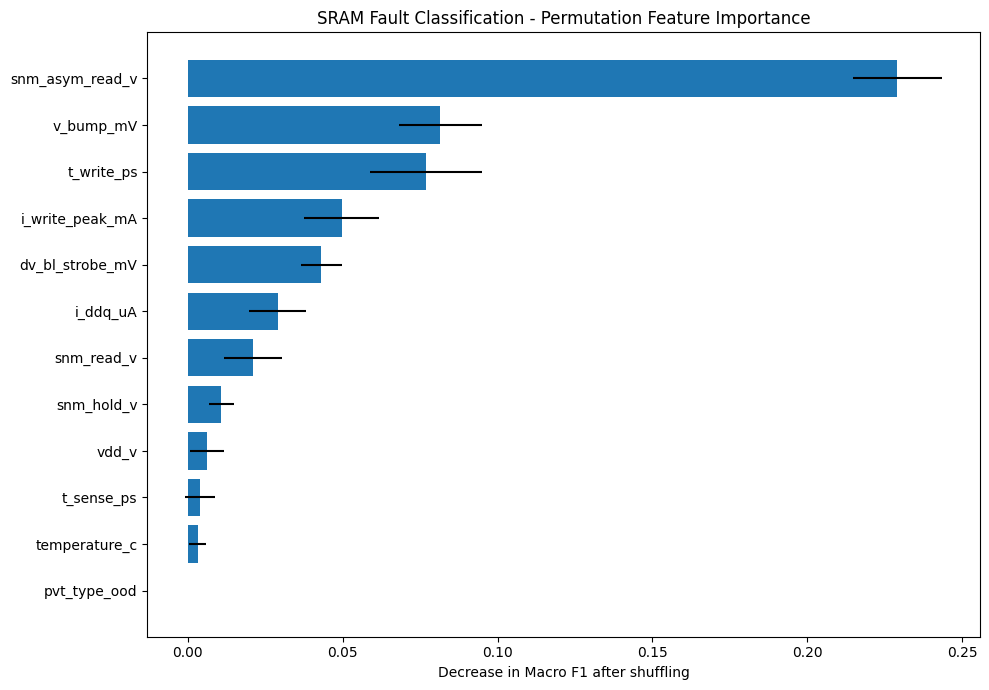

In [55]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.xlabel("Decrease in Macro F1 after shuffling")
plt.title("SRAM Fault Classification - Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [56]:
# Examine snm_asym_read_v
print("Overall statistics:")
display(df["snm_asym_read_v"].describe())

print("\nUnique values:")
print(df["snm_asym_read_v"].value_counts().head(15))

print("\nZero percentage:")
print((df["snm_asym_read_v"] == 0).mean() * 100)

Overall statistics:


count    450.000000
mean       0.000319
std        0.001312
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000100
max        0.015600
Name: snm_asym_read_v, dtype: float64


Unique values:
snm_asym_read_v
0.0000    317
0.0001     30
0.0002     20
0.0003     14
0.0006     10
0.0011      6
0.0008      6
0.0005      6
0.0004      6
0.0007      4
0.0013      3
0.0015      2
0.0012      2
0.0017      2
0.0022      2
Name: count, dtype: int64

Zero percentage:
70.44444444444444


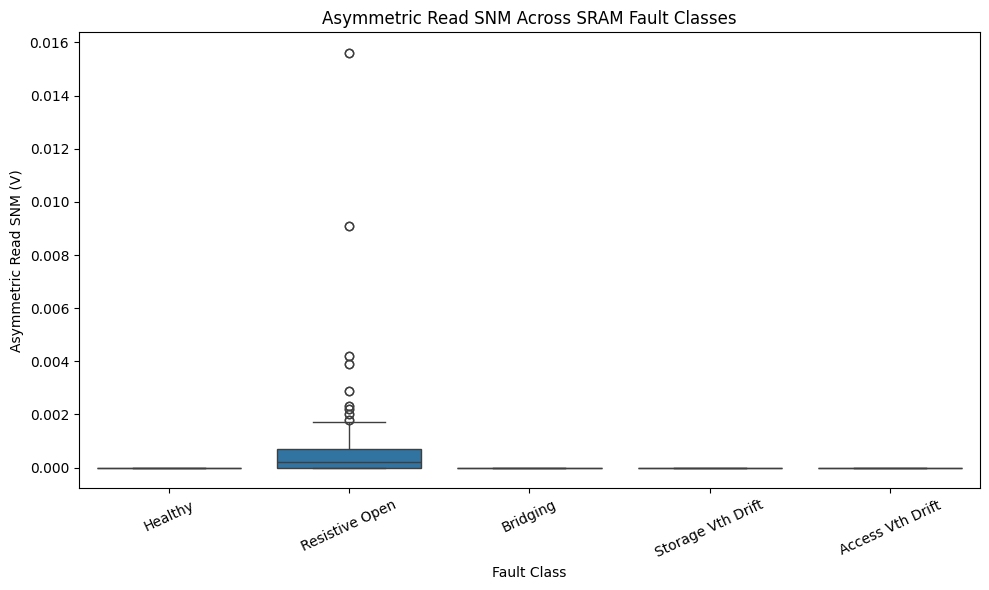

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="fault_class",
    y="snm_asym_read_v"
)

plt.xticks(
    [0, 1, 2, 3, 4],
    ["Healthy", "Resistive Open", "Bridging",
     "Storage Vth Drift", "Access Vth Drift"],
    rotation=25
)

plt.title("Asymmetric Read SNM Across SRAM Fault Classes")
plt.xlabel("Fault Class")
plt.ylabel("Asymmetric Read SNM (V)")
plt.tight_layout()
plt.show()

In [58]:
X_without_asym = X_cv.drop(
    columns=["snm_asym_read_v"],
    errors="ignore"
)

print("Original features:", X_cv.shape[1])
print("Features without asymmetric SNM:", X_without_asym.shape[1])

Original features: 12
Features without asymmetric SNM: 11


In [59]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Model A: All features
scores_all = cross_validate(
    rf,
    X_cv,
    y_cv,
    groups=groups_cv,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Model B: Without asymmetric read SNM
scores_without = cross_validate(
    rf,
    X_without_asym,
    y_cv,
    groups=groups_cv,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

comparison = pd.DataFrame([
    {
        "Dataset": "All Features",
        "Mean Accuracy": scores_all["test_accuracy"].mean(),
        "Mean Macro F1": scores_all["test_f1_macro"].mean()
    },
    {
        "Dataset": "Without snm_asym_read_v",
        "Mean Accuracy": scores_without["test_accuracy"].mean(),
        "Mean Macro F1": scores_without["test_f1_macro"].mean()
    }
])

display(comparison.round(4))

,Dataset,Mean Accuracy,Mean Macro F1
0,All Features,0.8133,0.7112
1,Without snm_asym_read_v,0.6422,0.5707


In [60]:
# Compare asymmetric SNM with convergence status

df["asym_snm_nonzero"] = (
    df["snm_asym_read_v"] > 0
)

print("Asymmetric SNM vs convergence:")
display(pd.crosstab(
    df["asym_snm_nonzero"],
    df["converged"],
    normalize="index"
).round(3))

print("\nAsymmetric SNM vs fault class:")
display(pd.crosstab(
    df["fault_class"],
    df["asym_snm_nonzero"],
    normalize="index"
).round(3))

Asymmetric SNM vs convergence:


converged,0,1
asym_snm_nonzero,,
False,0.445,0.555
True,0.053,0.947



Asymmetric SNM vs fault class:


asym_snm_nonzero,False,True
fault_class,,
0,1.000,0.000
1,0.261,0.739
2,1.000,0.000
3,1.000,0.000
4,1.000,0.000


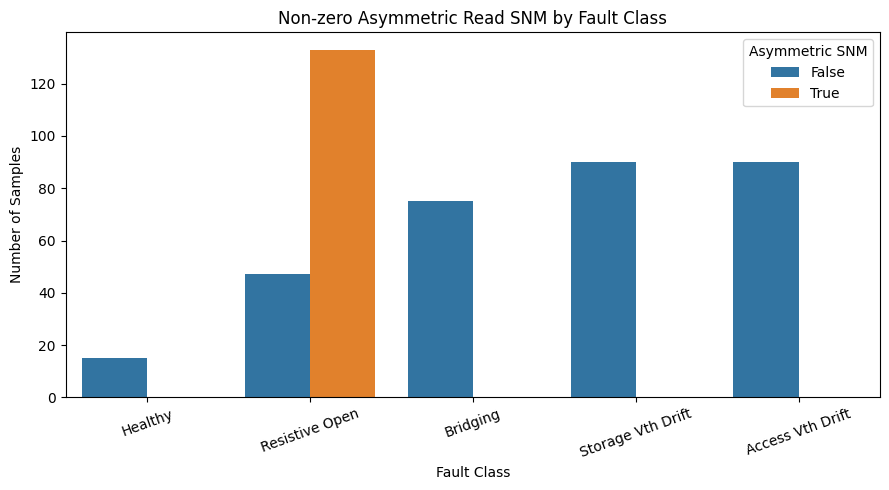

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="fault_class",
    hue="asym_snm_nonzero"
)

plt.title("Non-zero Asymmetric Read SNM by Fault Class")
plt.xlabel("Fault Class")
plt.ylabel("Number of Samples")
plt.xticks(
    [0, 1, 2, 3, 4],
    ["Healthy", "Resistive Open", "Bridging",
     "Storage Vth Drift", "Access Vth Drift"],
    rotation=20
)

plt.legend(title="Asymmetric SNM")
plt.tight_layout()
plt.show()

In [62]:
print("Asymmetric SNM vs convergence:")

display(pd.crosstab(
    df["asym_snm_nonzero"],
    df["converged"],
    margins=True
))

print("\nNormalized percentages:")

display(pd.crosstab(
    df["asym_snm_nonzero"],
    df["converged"],
    normalize="index"
).round(3) * 100)

Asymmetric SNM vs convergence:


converged,0,1,All
asym_snm_nonzero,,,
False,141,176,317
True,7,126,133
All,148,302,450



Normalized percentages:


converged,0,1
asym_snm_nonzero,,
False,44.5,55.5
True,5.3,94.7


In [63]:
# Restrict the analysis to Resistive Open samples
resistive_df = df[df["fault_class"] == 1].copy()

print("Resistive Open samples:", len(resistive_df))

print("\nAsymmetric SNM vs convergence within Resistive Open:")

display(pd.crosstab(
    resistive_df["asym_snm_nonzero"],
    resistive_df["converged"],
    margins=True
))

print("\nRow-wise percentages:")

display(pd.crosstab(
    resistive_df["asym_snm_nonzero"],
    resistive_df["converged"],
    normalize="index"
).round(3) * 100)

Resistive Open samples: 180

Asymmetric SNM vs convergence within Resistive Open:


converged,0,1,All
asym_snm_nonzero,,,
False,14,33,47
True,7,126,133
All,21,159,180



Row-wise percentages:


converged,0,1
asym_snm_nonzero,,
False,29.8,70.2
True,5.3,94.7


In [64]:
resistive_df = df[df["fault_class"] == 1].copy()

print("Resistive Open samples:", len(resistive_df))

display(pd.crosstab(
    resistive_df["asym_snm_nonzero"],
    resistive_df["converged"],
    margins=True
))

display(pd.crosstab(
    resistive_df["asym_snm_nonzero"],
    resistive_df["converged"],
    normalize="index"
).round(3) * 100)

Resistive Open samples: 180


converged,0,1,All
asym_snm_nonzero,,,
False,14,33,47
True,7,126,133
All,21,159,180


converged,0,1
asym_snm_nonzero,,
False,29.8,70.2
True,5.3,94.7


In [65]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [66]:
import shap
import matplotlib.pyplot as plt
import pandas as pd

In [67]:
from sklearn.ensemble import RandomForestClassifier

shap_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

shap_model.fit(X_cv, y_cv)

,n_estimators,300
,criterion,'gini'
,max_depth,8
,min_samples_split,10
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [68]:
from sklearn.ensemble import RandomForestClassifier

shap_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

shap_model.fit(X_cv, y_cv)

,n_estimators,300
,criterion,'gini'
,max_depth,8
,min_samples_split,10
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [69]:
explainer = shap.TreeExplainer(shap_model)

X_sample = X_cv.sample(
    n=min(150, len(X_cv)),
    random_state=42
)

shap_values = explainer.shap_values(X_sample)

print("SHAP analysis completed.")

SHAP analysis completed.


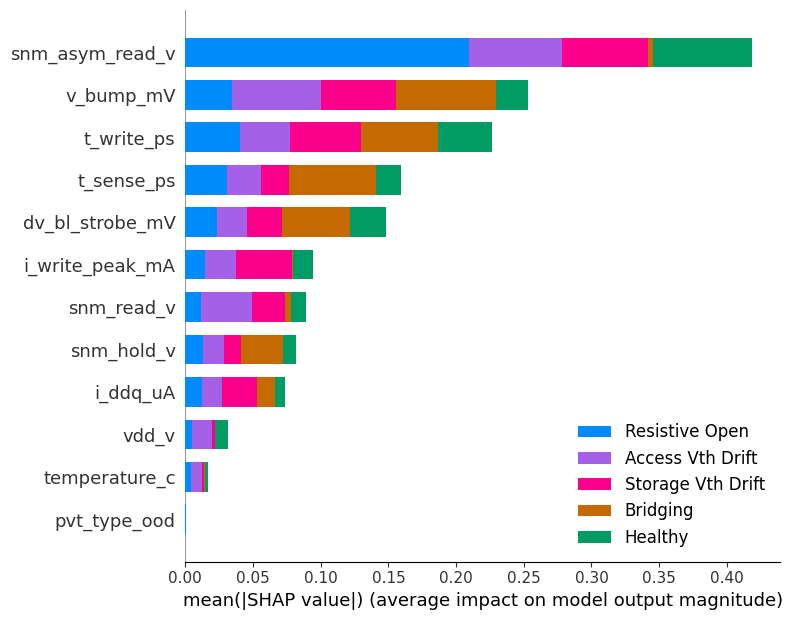

In [70]:
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar",
    class_names=[
        "Healthy",
        "Resistive Open",
        "Bridging",
        "Storage Vth Drift",
        "Access Vth Drift"
    ]
)

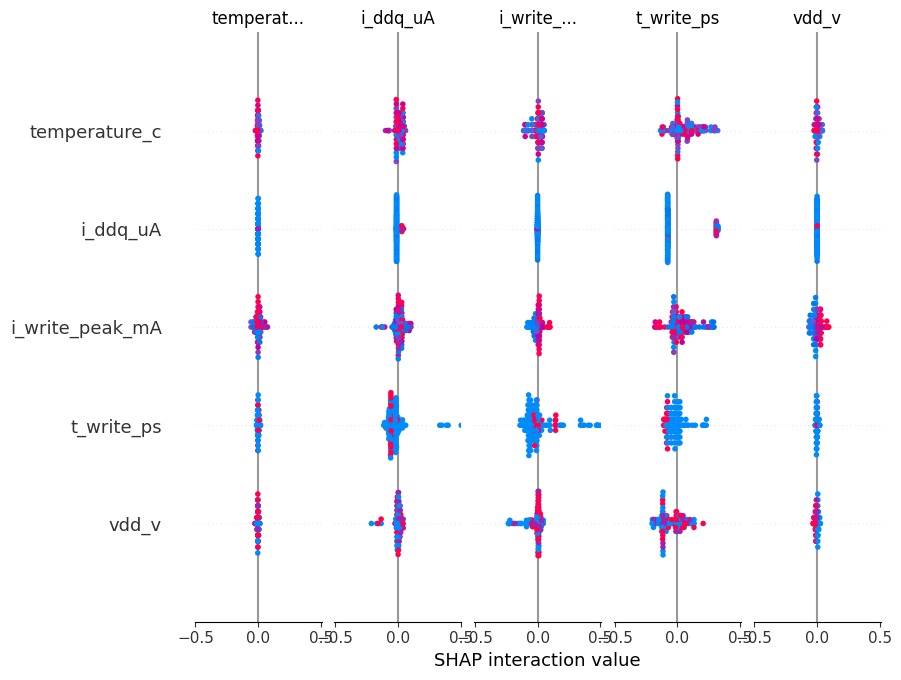

In [71]:
shap.summary_plot(
    shap_values,
    X_sample,
    class_names=[
        "Healthy",
        "Resistive Open",
        "Bridging",
        "Storage Vth Drift",
        "Access Vth Drift"
    ]
)

In [72]:
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_predictions = cross_val_predict(
    final_model,
    X_cv,
    y_cv,
    groups=groups_cv,
    cv=cv,
    n_jobs=-1
)

print("Final Accuracy:",
      accuracy_score(y_cv, final_predictions))

print("Final Macro F1:",
      f1_score(y_cv, final_predictions, average="macro"))

print("\nClassification Report:\n")

print(classification_report(
    y_cv,
    final_predictions,
    target_names=[
        "Healthy",
        "Resistive Open",
        "Bridging",
        "Storage Vth Drift",
        "Access Vth Drift"
    ],
    zero_division=0
))

Final Accuracy: 0.8133333333333334
Final Macro F1: 0.7038219314612209

Classification Report:

                   precision    recall  f1-score   support

          Healthy       0.17      0.13      0.15        15
   Resistive Open       0.99      0.74      0.85       180
         Bridging       1.00      1.00      1.00        75
Storage Vth Drift       0.71      0.93      0.80        90
 Access Vth Drift       0.65      0.80      0.72        90

         accuracy                           0.81       450
        macro avg       0.70      0.72      0.70       450
     weighted avg       0.84      0.81      0.82       450



In [73]:
import joblib
import os

final_model.fit(X_cv, y_cv)

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/sram_fault_classifier.pkl"
)

joblib.dump(
    list(X_cv.columns),
    "../models/feature_columns.pkl"
)

print("Model and feature columns saved successfully.")

Model and feature columns saved successfully.
